# Multi-Region Feature Ranking Analysis
This notebook analyzes the baseline Random Forest feature importance artifacts across biogeographic regions:
1. **Per-Region Top-N Importance Plots** grouped and colored by domain category.
2. **Cross-Region Commonality Analysis** (Upset / Overlap heatmap & Jaccard similarity of top features).
3. **Domain Category Distribution** across regions to evaluate spectral vs. topographic dependency.

In [1]:
from pathlib import Path
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

artifacts_dir = Path('data/feature_selection_artifacts')
TOP_N = 20
REGIONS = ['HIM']   # only these regions; other *_ranked_features.json files in the folder may be from older runs

# Locate all available region ranking JSONs
ranking_files = [artifacts_dir / f'{r}_ranked_features.json' for r in REGIONS]
print(f"Found {len(ranking_files)} region artifacts: {[f.stem.replace('_ranked_features', '') for f in ranking_files]}")

region_data = {}
for f in ranking_files:
    with open(f, 'r') as fp:
        content = json.load(fp)
        region_name = content.get('region', f.stem.replace('_ranked_features', ''))
        region_data[region_name] = content

regions = list(region_data.keys())
print(f"Loaded regions: {regions}")

Found 1 region artifacts: ['HIM']
Loaded regions: ['HIM']


In [2]:
# Categorization rule to segment features by domain sensor / thematic type
def categorize_feature(name: str) -> str:
    topo = {'elevation', 'slope', 'aspect_cos', 'aspect_sin', 'hand'}
    coords = {'lat', 'lon'}
    sma = {'gv', 'npv', 'soil', 'shade', 'ndfi'}
    bands = {'blue', 'green', 'red', 'nir', 'swir1', 'swir2', 'tir'}
    tasseled_cap = {'tcb', 'tcg', 'tcw'}
    indices = {'ndvi', 'evi2', 'mndwi', 'ndmi', 'bci', 'ibi'}
    landcover_masks = {'BareEarth', 'StableWater', 'TransientWater'}

    base_token = name.split('_')[0]
    if name in topo:
        return 'Topography / Hydrology'
    if name in coords:
        return 'Coordinates'
    if base_token in sma:
        return 'Spectral Unmixing (SMA)'
    if base_token in bands:
        return 'Surface Reflectance Bands'
    if base_token in indices:
        return 'Spectral Indices'
    if base_token in tasseled_cap:
        return 'Tasseled Cap'
    if name in landcover_masks:
        return 'Ancillary Masks'
    return 'Other'

CATEGORY_PALETTE = {
    'Topography / Hydrology': '#8c564b',
    'Coordinates': '#7f7f7f',
    'Spectral Indices': '#2ca02c',
    'Surface Reflectance Bands': '#1f77b4',
    'Spectral Unmixing (SMA)': '#ff7f0e',
    'Tasseled Cap': '#9467bd',
    'Ancillary Masks': '#17becf',
    'Other': '#d62728'
}

## 1. Top-N Ranked Features per Region (Colored by Category)

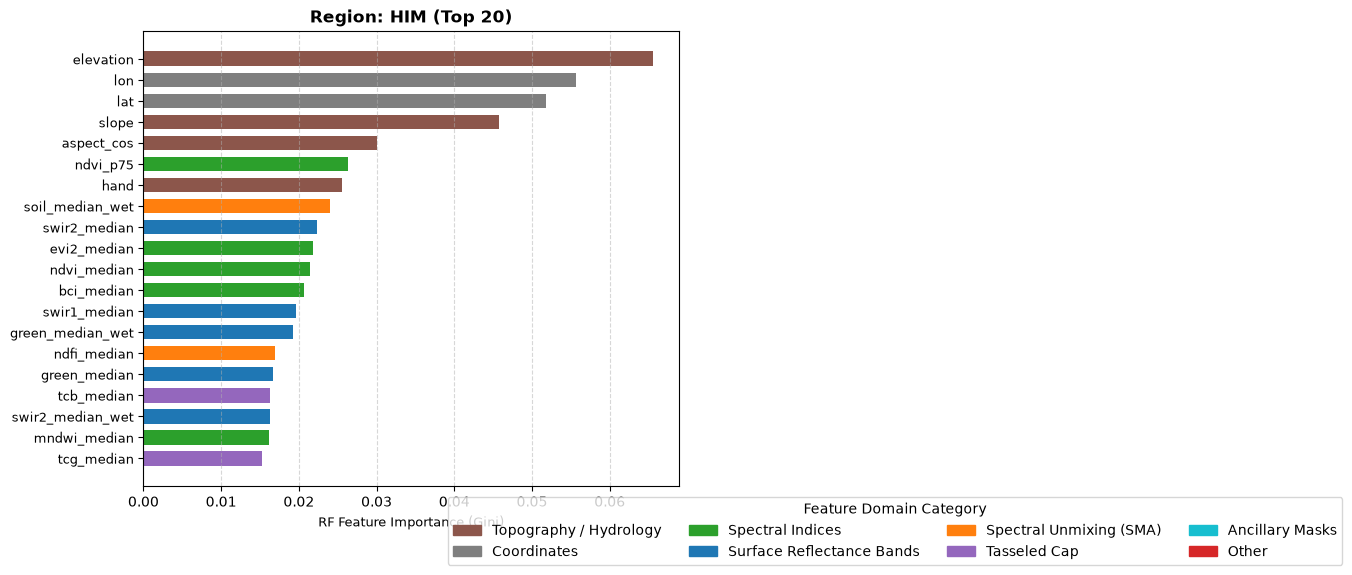

In [3]:
num_regions = len(regions)
cols = 3
rows = math.ceil(num_regions / cols)

fig, axes = plt.subplots(rows, cols, figsize=(18, rows * 5.5), squeeze=False)
axes = axes.flatten()

for idx, reg in enumerate(regions):
    ax = axes[idx]
    rf_data = region_data[reg]
    ranked_feats = rf_data['ranked_features'][:TOP_N]
    importances = [rf_data['feature_importances'][f] for f in ranked_feats]
    categories = [categorize_feature(f) for f in ranked_feats]
    colors = [CATEGORY_PALETTE.get(c, '#333333') for c in categories]

    # Horizontal bar plot (topmost feature at the top)
    y_pos = np.arange(len(ranked_feats))
    ax.barh(y_pos, importances[::-1], color=colors[::-1], edgecolor='none', height=0.7)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(ranked_feats[::-1], fontsize=9)
    ax.set_title(f"Region: {reg} (Top {TOP_N})", fontsize=12, fontweight='bold')
    ax.set_xlabel('RF Feature Importance (Gini)', fontsize=9)
    ax.grid(axis='x', linestyle='--', alpha=0.5)

# Hide unused axes
for extra_idx in range(num_regions, len(axes)):
    fig.delaxes(axes[extra_idx])

# Shared category legend
legend_handles = [
    mpatches.Patch(color=col, label=cat)
    for cat, col in CATEGORY_PALETTE.items()
]
fig.legend(
    handles=legend_handles,
    loc='lower center',
    ncol=4,
    bbox_to_anchor=(0.5, -0.05),
    frameon=True,
    title="Feature Domain Category",
    fontsize=10
)

plt.tight_layout()
plt.show()

## 2. Cross-Region Top-N Comparison & Overlap Matrix

Features in Top 20 across ALL 1 regions (20): ['aspect_cos', 'bci_median', 'elevation', 'evi2_median', 'green_median', 'green_median_wet', 'hand', 'lat', 'lon', 'mndwi_median', 'ndfi_median', 'ndvi_median', 'ndvi_p75', 'slope', 'soil_median_wet', 'swir1_median', 'swir2_median', 'swir2_median_wet', 'tcb_median', 'tcg_median']


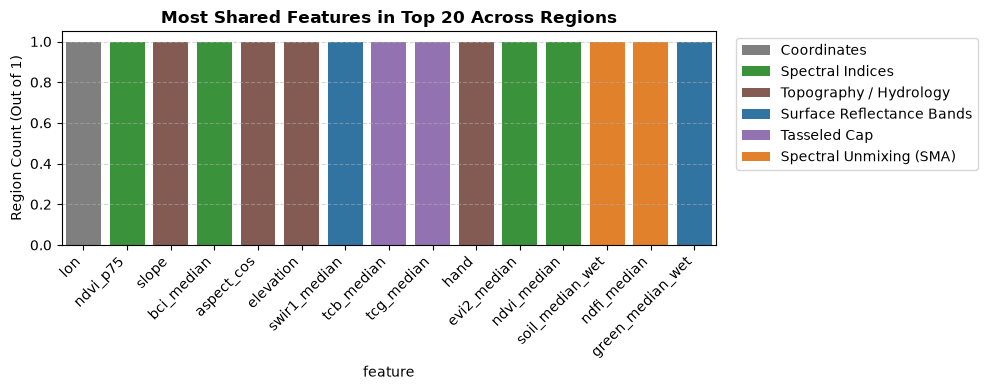

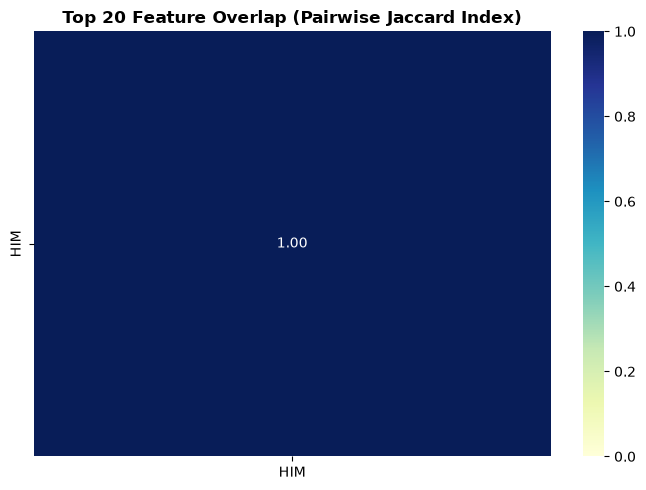

In [4]:
# Top-N sets per region
top_n_sets = {reg: set(region_data[reg]['ranked_features'][:TOP_N]) for reg in regions}

# Strict intersection across all regions
universal_top = set.intersection(*top_n_sets.values())
print(f"Features in Top {TOP_N} across ALL {len(regions)} regions ({len(universal_top)}): {sorted(universal_top)}")

# Frequency table of features appearing in Top-N across groups
all_top_features = [feat for s in top_n_sets.values() for feat in s]
freq_series = pd.Series(all_top_features).value_counts()
freq_df = pd.DataFrame({
    'feature': freq_series.index,
    'region_count': freq_series.values,
    'category': [categorize_feature(f) for f in freq_series.index]
})

plt.figure(figsize=(10, 4))
sns.barplot(data=freq_df.head(15), x='feature', y='region_count', hue='category', palette=CATEGORY_PALETTE, dodge=False)
plt.title(f"Most Shared Features in Top {TOP_N} Across Regions", fontweight='bold')
plt.ylabel(f"Region Count (Out of {len(regions)})")
plt.xticks(rotation=45, ha='right')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Pairwise Jaccard overlap heatmap
jaccard_mat = pd.DataFrame(index=regions, columns=regions, dtype=float)
for r1 in regions:
    for r2 in regions:
        s1, s2 = top_n_sets[r1], top_n_sets[r2]
        jaccard_mat.loc[r1, r2] = len(s1 & s2) / len(s1 | s2)

plt.figure(figsize=(7, 5))
sns.heatmap(jaccard_mat.astype(float), annot=True, fmt=".2f", cmap='YlGnBu', vmin=0, vmax=1)
plt.title(f'Top {TOP_N} Feature Overlap (Pairwise Jaccard Index)', fontweight='bold')
plt.tight_layout()
plt.show()

## 3. Category Proportion Breakdown across Regions

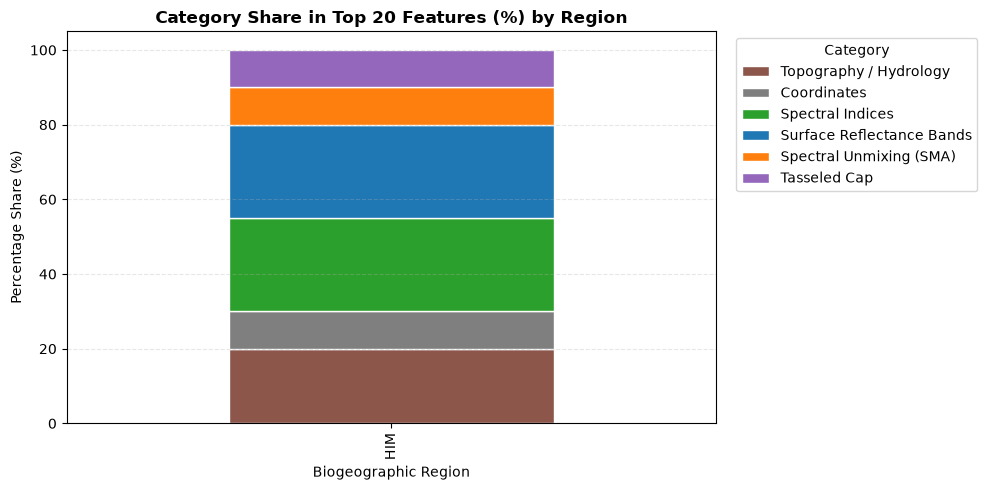

In [5]:
cat_rows = []
for reg in regions:
    top_feats = region_data[reg]['ranked_features'][:TOP_N]
    for f in top_feats:
        cat_rows.append({'region': reg, 'feature': f, 'category': categorize_feature(f)})

cat_df = pd.DataFrame(cat_rows)
cross_tab = pd.crosstab(cat_df['region'], cat_df['category'], normalize='index') * 100

# Ensure columns align with defined palette
palette_ordered_cols = [c for c in CATEGORY_PALETTE.keys() if c in cross_tab.columns]
cross_tab = cross_tab[palette_ordered_cols]

ax = cross_tab.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 5),
    color=[CATEGORY_PALETTE[c] for c in cross_tab.columns],
    edgecolor='white'
)
plt.title(f'Category Share in Top {TOP_N} Features (%) by Region', fontweight='bold')
plt.ylabel('Percentage Share (%)')
plt.xlabel('Biogeographic Region')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Category')
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
    if 'ranked_features' in rf_data:
        df_rank = pd.DataFrame(rf_data['ranked_features'])
    else:
        df_rank = pd.DataFrame(rf_data)

In [7]:
df_rank

,0
0,elevation
1,lon
2,lat
3,slope
4,aspect_cos
...,...
98,green_mad
99,blue_swing
100,blue_mad
101,npv_swing


In [8]:
# Robust parser to extract a 2-column DataFrame from your JSON files
def extract_ranking_df(rf_data: dict) -> pd.DataFrame:
    if "feature_importances" in rf_data and isinstance(rf_data["feature_importances"], dict):
        fi = rf_data["feature_importances"]
        df = pd.DataFrame(list(fi.items()), columns=["feature", "importance"])
    elif "ranked_features" in rf_data and isinstance(rf_data["ranked_features"], list):
        first_item = rf_data["ranked_features"][0] if rf_data["ranked_features"] else None
        if isinstance(first_item, dict):
            df = pd.DataFrame(rf_data["ranked_features"])
        else:
            # Fallback if only string list exists without numeric importances
            df = pd.DataFrame({
                "feature": rf_data["ranked_features"],
                "importance": list(range(len(rf_data["ranked_features"]), 0, -1))
            })
    else:
        raise ValueError("Unrecognized feature importance artifact format.")
    return df

# Mapping base spectral/band tokens to target application domains
APPLICATION_DOMAIN_MAP = {
    # Vegetation & Canopy
    "ndvi": "Vegetation & Canopy",
    "evi2": "Vegetation & Canopy",
    "tcg": "Vegetation & Canopy",
    "gv": "Vegetation & Canopy",
    "red": "Vegetation & Canopy",
    "nir": "Vegetation & Canopy",
    # Water & Moisture
    "mndwi": "Water & Moisture",
    "ndmi": "Water & Moisture",
    "tcw": "Water & Moisture",
    "hand": "Water & Moisture",
    "StableWater": "Water & Moisture",
    "TransientWater": "Water & Moisture",
    # Soil, Tillage & Built-up
    "bci": "Soil & Built-up",
    "ibi": "Soil & Built-up",
    "tcb": "Soil & Built-up",
    "soil": "Soil & Built-up",
    "npv": "Soil & Built-up",
    "BareEarth": "Soil & Built-up",
    "swir1": "Soil & Built-up",
    "swir2": "Soil & Built-up",
    # Thermal / Energy
    "tir": "Thermal / Energy",
    "shade": "Thermal / Energy",
    # Disturbance
    "ndfi": "Forest Disturbance",
    # Topography / Terrain
    "elevation": "Topography",
    "slope": "Topography",
    "aspect_cos": "Topography",
    "aspect_sin": "Topography",
    # Geography & Visible
    "lat": "Coordinates",
    "lon": "Coordinates",
    "blue": "Atmospheric / Visible",
    "green": "Atmospheric / Visible",
}

APPLICATION_PALETTE = {
    "Vegetation & Canopy": "#2ca02c",
    "Water & Moisture": "#1f77b4",
    "Soil & Built-up": "#d95f02",
    "Thermal / Energy": "#e7298a",
    "Forest Disturbance": "#7570b3",
    "Topography": "#8c564b",
    "Coordinates": "#7f7f7f",
    "Atmospheric / Visible": "#17becf",
    "Other": "#333333",
}

def map_feature_to_domain(feature_name: str) -> str:
    base = feature_name.split("_")[0]
    if feature_name in APPLICATION_DOMAIN_MAP:
        return APPLICATION_DOMAIN_MAP[feature_name]
    return APPLICATION_DOMAIN_MAP.get(base, "Other")

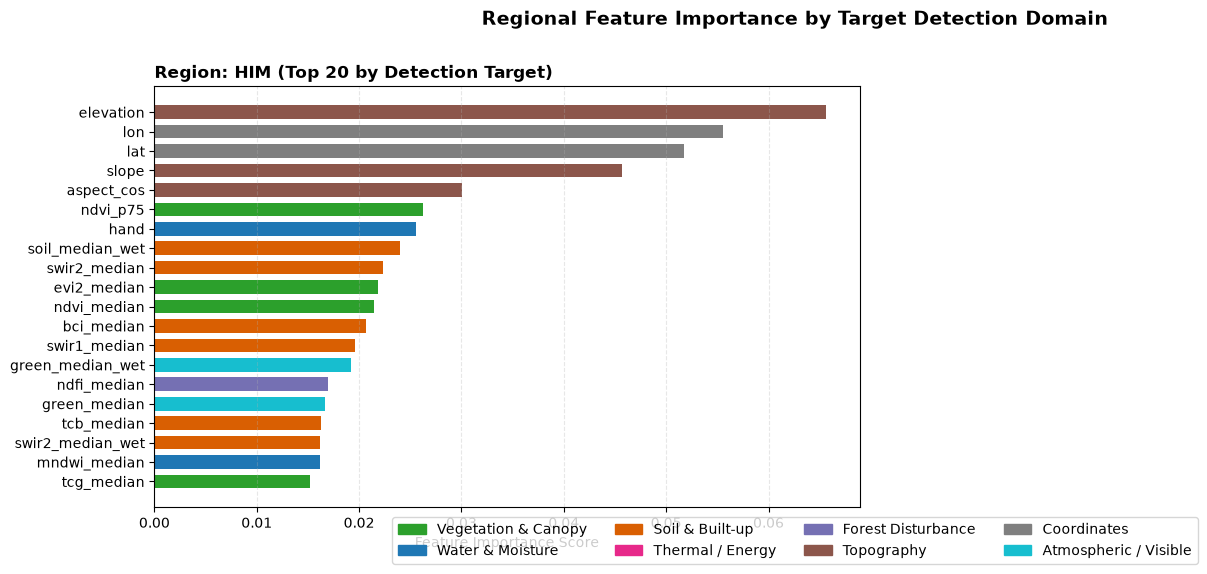

In [9]:
n_regions = len(regions)
cols = 2
rows = math.ceil(n_regions / cols)

fig, axes = plt.subplots(rows, cols, figsize=(16, rows * 5.5), sharex=False)
axes = axes.flatten()

for idx, region in enumerate(regions):
    ax = axes[idx]
    df_rank = extract_ranking_df(region_data[region])

    # Select and sort Top-N
    df_top = (
        df_rank.sort_values(by="importance", ascending=False)
        .head(TOP_N)
        .copy()
    )
    df_top["domain"] = df_top["feature"].apply(map_feature_to_domain)
    df_top = df_top.iloc[::-1]  # Invert so highest score is at top

    bar_colors = [
        APPLICATION_PALETTE.get(d, "#333333") for d in df_top["domain"]
    ]

    ax.barh(
        df_top["feature"],
        df_top["importance"],
        color=bar_colors,
        height=0.7,
        edgecolor="none",
    )
    ax.set_title(
        f"Region: {region} (Top {TOP_N} by Detection Target)",
        fontsize=12,
        fontweight="bold",
        loc="left",
    )
    ax.set_xlabel("Feature Importance Score", fontsize=10)
    ax.grid(axis="x", linestyle="--", alpha=0.3)

# Remove unused axes if region count is odd
for j in range(idx + 1, len(axes)):
    fig.delaxes(axes[j])

# Global Legend
legend_patches = [
    mpatches.Patch(color=c, label=d)
    for d, c in APPLICATION_PALETTE.items()
    if d != "Other"
]
fig.legend(
    handles=legend_patches,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.01),
    ncol=4,
    fontsize=10,
    frameon=True,
)

plt.suptitle(
    "Regional Feature Importance by Target Detection Domain",
    fontsize=14,
    fontweight="bold",
    y=1.01,
)

plt.tight_layout()
plt.show()